# 01 — Reproduce Defense-Prefix evaluation with the authors' pretrained DP vector

**Goal:** check that the evaluation pipeline and data work *before* any training.
We use the authors' released token `learned_token/dp_vit-b32.pt` (no training) and compare with the paper's Table 3 / Table B.

| Dataset | Condition | Paper: CLIP | Paper: CLIP + DP |
|---|---|---|---|
| RTA-100 | real-world attack | 47.20 | 58.00 |
| Oxford Pets | clean | 87.35 | 87.22 |
| Oxford Pets | synthetic attack | 58.95 | 72.88 |

**Decision rule (written before running):** if our numbers are within ~2 points of the paper, the evaluation pipeline is OK and we move on.
If not, we investigate before going further.

Runtime: **GPU (T4)**. Runtime → Change runtime type → T4 GPU.

In [ ]:
# 1) Environment check — keep this output for the report
!nvidia-smi --query-gpu=name,memory.total --format=csv
import sys, torch, platform
print("python", sys.version.split()[0], "| torch", torch.__version__, "| cuda", torch.version.cuda, "| platform", platform.platform())

name, memory.total [MiB]
Tesla T4, 15360 MiB
python 3.13.16 | torch 2.11.0+cu130 | cuda 13.0 | platform Linux-6.6.159+-x86_64-with-glibc2.39


In [ ]:
# 2) Get the original code, pinned to the exact commit we analysed
%cd /content
!rm -rf Defense-Prefix
!git clone -q https://github.com/azuma164/Defense-Prefix.git
%cd /content/Defense-Prefix
!git checkout -q 50d7887
!git rev-parse HEAD

/content
/content/Defense-Prefix
50d7887017b295e76b15e56c137ab47e68264448


In [ ]:
# 3) Dependencies (OpenAI CLIP package + its requirements)
!pip -q install ftfy regex git+https://github.com/openai/CLIP.git
import PIL; print("Pillow", PIL.__version__)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Pillow 11.3.0


### Deviations from the original code (record these in the report)
1. **Pillow ≥ 10 removed `ImageDraw.textsize`**, which the attack-generation code uses. We replace it with an equivalent built on `multiline_textbbox`. This can shift text placement/size by a pixel or so, so our synthetic test images are *not* byte-identical to the authors' (they did not release their synthetic test images anyway).
2. **`torch.load` default changed in PyTorch ≥ 2.6** (`weights_only=True`). We pass `weights_only=False` and `map_location` so the released token loads on the current runtime.

No other code is changed.

In [ ]:
# 4) Apply the two minimal compatibility patches
import re, pathlib
p = pathlib.Path("datasets/utils/make_dataset_train.py")
s = p.read_text()
helper = '''
def _textsize(draw, text, font):
    # Replacement for ImageDraw.textsize (removed in Pillow 10).
    l, t, r, b = draw.multiline_textbbox((0, 0), text, font=font)
    return r, b
'''
if "_textsize" not in s:
    s = s.replace('random.seed(300)', 'random.seed(300)\n' + helper, 1)
    s = s.replace('imagedraw.textsize(text, font=font)', '_textsize(imagedraw, text, font)')
    p.write_text(s)

e = pathlib.Path("eval.py")
s = e.read_text()
s = s.replace("torch.load(args.tokens_path)", "torch.load(args.tokens_path, map_location=device, weights_only=False)")
e.write_text(s)
!git diff --stat

 datasets/utils/make_dataset_train.py | 10 ++++++++--
 eval.py                              |  2 +-
 2 files changed, 9 insertions(+), 3 deletions(-)


In [ ]:
# 5) RTA-100 ships inside the repo; the loader expects datasets/ours/data/
!unzip -q -o rta100.zip -d /tmp/rta
!mkdir -p datasets/ours && rm -rf datasets/ours/data && mv /tmp/rta/rta100 datasets/ours/data
!ls datasets/ours/data | wc -l   # expect 1000

1000


In [ ]:
# 6) Evaluate on RTA-100 (real-world attacks). Prints CLIP and CLIP + DP accuracy.
!mkdir -p logs
!python eval.py --dataset=rta-100 2>&1 | grep -v "^label=" | tee logs/rta100.txt

100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 166MiB/s]
args.tokens_path:  ./learned_token/dp_vit-b32.pt
CLIP:  46.7& 46.7
CLIP + Defense-Prefix:  57.7& 57.7


In [ ]:
# 7) Oxford Pets: first run downloads (~800 MB) and generates the synthetic attack images (seed 300)
!python eval.py --dataset=pets    2>&1 | tail -3 | tee logs/pets_clean.txt
!python eval.py --dataset=pets -t 2>&1 | tail -3 | tee logs/pets_attack.txt

100%|██████████| 19.2M/19.2M [00:02<00:00, 9.26MB/s]
CLIP:  87.38& 87.38
CLIP + Defense-Prefix:  87.22& 87.22
args.tokens_path:  ./learned_token/dp_vit-b32.pt
CLIP:  59.25& 59.25
CLIP + Defense-Prefix:  72.44& 72.44


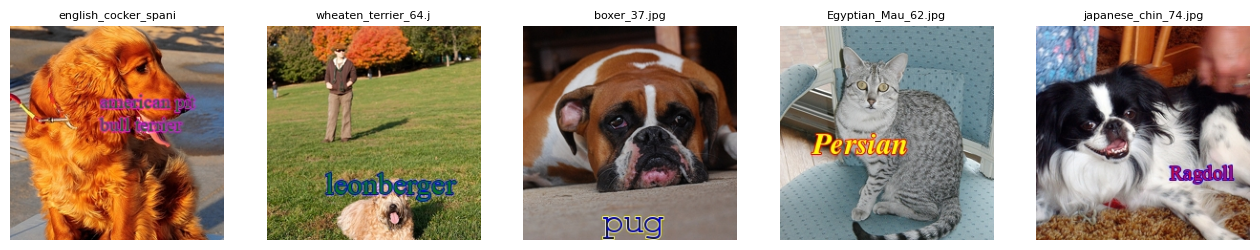

In [ ]:
# 8) Look at a few attacked images to check the attack looks like the paper's Figure B
import glob, random
from PIL import Image
import matplotlib.pyplot as plt
files = sorted(glob.glob("datasets/oxford-iiit-pet/typographic_images/*.jpg"))
random.Random(0).shuffle(files)
fig, axs = plt.subplots(1, 5, figsize=(16, 4))
for ax, f in zip(axs, files[:5]):
    ax.imshow(Image.open(f)); ax.axis("off"); ax.set_title(f.split("/")[-1][:20], fontsize=8)
plt.show()

In [ ]:
# 9) Collect results next to the paper's numbers
import re
paper = {"rta100": (47.20, 58.00), "pets_clean": (87.35, 87.22), "pets_attack": (58.95, 72.88)}
def parse(path):
    txt = open(path).read()
    clip = re.search(r"CLIP:\s*([\d.]+)", txt); dp = re.search(r"Defense-Prefix:\s*([\d.]+)", txt)
    return float(clip.group(1)), float(dp.group(1))
print(f"{'setting':<13}{'paper CLIP':>11}{'ours CLIP':>10}{'paper DP':>10}{'ours DP':>9}")
for k in paper:
    c, d = parse(f"logs/{k}.txt")
    print(f"{k:<13}{paper[k][0]:>11.2f}{c:>10.2f}{paper[k][1]:>10.2f}{d:>9.2f}")

setting       paper CLIP ours CLIP  paper DP  ours DP
rta100             47.20     46.70     58.00    57.70
pets_clean         87.35     87.38     87.22    87.22
pets_attack        58.95     59.25     72.88    72.44


In [ ]:
# 10) Save environment for the report / repository
!pip freeze > logs/pip_freeze.txt
!git rev-parse HEAD > logs/commit.txt
!git diff > logs/patches.diff
!zip -q -r step1_logs.zip logs
from google.colab import files; files.download("step1_logs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>